# Speech Communication: excercise 1
### Week October 19-25 2026

##### Excercise 1.1: Input audio data

Sampling frequency is:  16000
Number of samples is:  45466
duration of the signal in seconds is: 2.841625
Highest amplitude in the signal is: 0.75


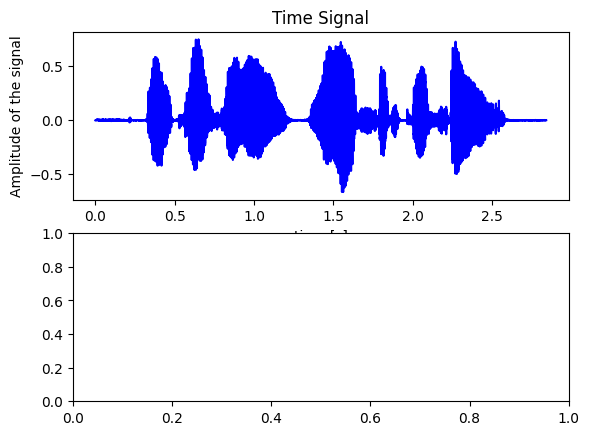

In [27]:
import numpy as np
import matplotlib.pyplot as pyplot
import librosa

(sample, sample_rate)=librosa.load("13ZZ637A.wav", sr=None)

sample_count=len(sample)

duration_sec=sample_count/sample_rate
time=np.linspace(0,duration_sec, num=sample_count)

figure, (time_diagram, zero_crossing_diagram) = pyplot.subplots(2, 1)
time_diagram.plot(time, sample, color='b')
time_diagram.set(xlabel='time [s]', ylabel='Amplitude of the signal', title='Time Signal')


#printing the results:
print("Sampling frequency is: ", sample_rate)
print("Number of samples is: ", sample_count)
print("duration of the signal in seconds is:", duration_sec)

max_amplitude = max(abs(sample))
print("Highest amplitude in the signal is:", max_amplitude)

##### Excercise 1.2: Zero crossing rate

In [ ]:
def compute_zero_crossing(samples: np.ndarray) -> np.ndarray:
    """
        Indicates the positions of where a 1D vector of samples touches or crosses zero.

        returns: 1D vector of 0-1-zero indicators, 1 indicates a new zero (before or at the current sample), 0 indicates otherwise.
    """

    sample_count=len(sample)
    zero_crossing=np.zeros(sample_count)
    for i in range(1,sample_count):
        if (0 != np.sign(sample[i-1]) != np.sign(sample[i])): #checks if signs are different
            zero_crossing[i]=1
    return zero_crossing

zero_crossings=compute_zero_crossing(sample)

number_of_zero_crossings=int(sum(zero_crossings))

print('Number of all zero crossings in the signal is:', number_of_zero_crossings )

def compute_zero_crossing_rates(interval_length: int, zero_crossings: np.ndarray):
    """
    Specify an interval length as a number of samples to sum together, and a vector of zero crossing indicators (0-1-vector).

    returns: a vector which sums up the zero crossings in the previous interval until the corresponding zero-crossing at index i
    """
    zero_crossing_intervals = np.ones(interval_length)
    result = np.convolve(zero_crossings, zero_crossing_intervals)
    return result[:len(zero_crossings)]

sample_count_10ms = int(0.01 * sample_rate)
zero_crossings_rates_per_10ms = compute_zero_crossing_rates(sample_count_10ms, zero_crossings)

zero_crossing_diagram.plot(time, zero_crossings_rates_per_10ms)
zero_crossing_diagram.set(title='10ms Cumulated Zero Crossings', xlabel='Interval end time [s]', ylabel='Number of zero crossings')


pyplot.show()

Number of all zero crossings in the signal is: 6853
